In [1]:
# TH 5.1
import numpy as np
P = np.zeros((10, 10), dtype=int)
P[0, 0] = 1
for i in range(1, 10):
    P[i, 0] = 1
    P[i, 1:] = P[i-1, 1:] + P[i-1, :-1]
print("Tam giac Pascal:")
print(P)
print("Hang 4:", P[4, :5])
print("Hang 9:", P[9, :10])
print("C(9,4) =", P[9, 4])
print("Tong hang 9 =", P[9].sum())
assert P[9, 4] == 126
assert P[9].sum() == 2**9
print("Kiem tra thanh cong!")

Tam giac Pascal:
[[  1   0   0   0   0   0   0   0   0   0]
 [  1   1   0   0   0   0   0   0   0   0]
 [  1   2   1   0   0   0   0   0   0   0]
 [  1   3   3   1   0   0   0   0   0   0]
 [  1   4   6   4   1   0   0   0   0   0]
 [  1   5  10  10   5   1   0   0   0   0]
 [  1   6  15  20  15   6   1   0   0   0]
 [  1   7  21  35  35  21   7   1   0   0]
 [  1   8  28  56  70  56  28   8   1   0]
 [  1   9  36  84 126 126  84  36   9   1]]
Hang 4: [1 4 6 4 1]
Hang 9: [  1   9  36  84 126 126  84  36   9   1]
C(9,4) = 126
Tong hang 9 = 512
Kiem tra thanh cong!


In [2]:
# TH 5.6
import numpy as np
A = np.array([
    [2,  1, -1, 0],
    [1,  3,  2, 1],
    [0, -1,  4, 2],
    [3,  0,  1, 5]
], dtype=float)
x_dung = np.array([1, -1, 2, 3], dtype=float)
b = A @ x_dung
print("Vector b =", b)
x = np.linalg.solve(A, b)
print("Nghiem tim duoc:", x)
print("Dinh thuc A:", round(np.linalg.det(A), 6))
print("Nghiem dung:", np.allclose(x, x_dung))
assert np.allclose(x, x_dung)
A_moi = A.copy()
A_moi[3] = A_moi[0] + A_moi[1]
print("Ma tran A sau khi thay hang 4:")
print(A_moi)
print("Dinh thuc A moi:",
      round(np.linalg.det(A_moi), 6))
try:
    x_moi = np.linalg.solve(A_moi, b)
    print("Nghiem moi:", x_moi)
except np.linalg.LinAlgError as e:
    print("Loi:", e)

Vector b = [-1.  5. 15. 20.]
Nghiem tim duoc: [ 1. -1.  2.  3.]
Dinh thuc A: 92.0
Nghiem dung: True
Ma tran A sau khi thay hang 4:
[[ 2.  1. -1.  0.]
 [ 1.  3.  2.  1.]
 [ 0. -1.  4.  2.]
 [ 3.  4.  1.  1.]]
Dinh thuc A moi: -0.0
Nghiem moi: [ 2.32801458e+17 -6.65147022e+16  3.99088213e+17 -8.31433777e+17]


In [3]:
# TH 5.7
import numpy as np
x = np.array([0, 1, 2, 3], dtype=float)
y = np.array([1, 0, 5, 22], dtype=float)
V = np.vander(x, increasing=True)
print("Ma tran Vandermonde:")
print(V)
c = np.linalg.solve(V, y)
print("Cac he so c0, c1, c2, c3:")
print(c)
y_tinh = V @ c
print("Gia tri tinh lai:", y_tinh)
print("Kiem tra:", np.allclose(y_tinh, y))
assert np.allclose(y_tinh, y)
x_moi = 1.5
p = c[0] + c[1]*x_moi + c[2]*x_moi**2 + c[3]*x_moi**3
print("p(1.5) =", p)

Ma tran Vandermonde:
[[ 1.  0.  0.  0.]
 [ 1.  1.  1.  1.]
 [ 1.  2.  4.  8.]
 [ 1.  3.  9. 27.]]
Cac he so c0, c1, c2, c3:
[ 1.00000000e+00 -2.00000000e+00 -1.33226763e-15  1.00000000e+00]
Gia tri tinh lai: [ 1.0000000e+00 -8.8817842e-16  5.0000000e+00  2.2000000e+01]
Kiem tra: True
p(1.5) = 1.3749999999999982


In [4]:
# TH 5.8
import numpy as np
import time
rng = np.random.default_rng(0)
A = rng.random((500, 500))
b = rng.random(500)
t1 = time.perf_counter()
x1 = np.linalg.solve(A, b)
t2 = time.perf_counter()
thoi_gian_solve = t2 - t1
t3 = time.perf_counter()
x2 = np.linalg.inv(A) @ b
t4 = time.perf_counter()
thoi_gian_inv = t4 - t3
sai_so_1 = np.linalg.norm(A @ x1 - b)
sai_so_2 = np.linalg.norm(A @ x2 - b)
print("PHUONG PHAP SOLVE")
print(f"Thoi gian: {thoi_gian_solve:.6f} giay")
print(f"Sai so phan du: {sai_so_1:.10e}")
print("\nPHUONG PHAP INV")
print(f"Thoi gian: {thoi_gian_inv:.6f} giay")
print(f"Sai so phan du: {sai_so_2:.10e}")
print("\nHai nghiem gan bang nhau:",
      np.allclose(x1, x2))
assert sai_so_1 < 1e-7
assert sai_so_2 < 1e-7
assert np.allclose(x1, x2)
print("Kiem tra thanh cong!")

PHUONG PHAP SOLVE
Thoi gian: 0.441146 giay
Sai so phan du: 1.1279834910e-12

PHUONG PHAP INV
Thoi gian: 0.270591 giay
Sai so phan du: 2.4649414731e-12

Hai nghiem gan bang nhau: True
Kiem tra thanh cong!


In [5]:
# TH 6.2
import pandas as pd
ds = []
while True:
    ho_ten = input("Nhap ho ten (Enter de dung): ").strip()
    if ho_ten == "":
        break
    ma_sv = input("Nhap ma sinh vien: ").strip()
    ngay_sinh = input("Nhap ngay sinh (dd/mm/yyyy): ").strip()
    ds.append([ho_ten, ma_sv, ngay_sinh])
df = pd.DataFrame(ds, columns=["Ho_ten", "Ma_SV", "Ngay_sinh"])
print("Danh sach sinh vien:")
print(df)

Nhap ho ten (Enter de dung):  Pham Hoang Thang
Nhap ma sinh vien:  233030612
Nhap ngay sinh (dd/mm/yyyy):  22/01/2005
Nhap ho ten (Enter de dung):  Nguyen Dang Thuy AN
Nhap ma sinh vien:  233030610
Nhap ngay sinh (dd/mm/yyyy):  13/08/2005
Nhap ho ten (Enter de dung):  


Danh sach sinh vien:
                Ho_ten      Ma_SV   Ngay_sinh
0     Pham Hoang Thang  233030612  22/01/2005
1  Nguyen Dang Thuy AN  233030610  13/08/2005


In [6]:
df["Ngay_sinh"] = pd.to_datetime(
    df["Ngay_sinh"],
    format="%d/%m/%Y"
)
moc = pd.Timestamp("2026-01-01")
df["Tuoi"] = ((moc - df["Ngay_sinh"]).dt.days / 365.25).astype(int)
print(df)

                Ho_ten      Ma_SV  Ngay_sinh  Tuoi
0     Pham Hoang Thang  233030612 2005-01-22    20
1  Nguyen Dang Thuy AN  233030610 2005-08-13    20


In [8]:
df.to_excel("students.xlsx", index=False)
print("Da luu file students.xlsx")
df_moi = pd.read_excel(
    "students.xlsx",
    dtype={"Ma_SV": str}
)
print("Du lieu doc lai:")
print(df_moi)
assert df_moi.equals(df)
print("Kiem tra thanh cong!")

Da luu file students.xlsx
Du lieu doc lai:
                Ho_ten      Ma_SV  Ngay_sinh  Tuoi
0     Pham Hoang Thang  233030612 2005-01-22    20
1  Nguyen Dang Thuy AN  233030610 2005-08-13    20
Kiem tra thanh cong!


1. THONG TIN DU LIEU
Kich thuoc: (200, 3)
So gia tri thieu ban dau:
Index             0
Height(Inches)    3
Weight(Pounds)    4
dtype: int64

2. DU LIEU SAU KHI XU LY
   Index  Height_in  Weight_lb  Height_cm  Weight_kg        BMI
0      1      65.78     112.99   167.0812  51.251402  18.359066
1      2      71.52     136.49   181.6608  61.910823  18.760488
2      3      69.40     153.03   176.2760  69.413240  22.338600
3      4      68.22     142.34   173.2788  64.564338  21.503138
4      5      67.79     144.30   172.1866  65.453379  22.076660

So gia tri thieu:
Height_cm    0
Weight_kg    0
BMI          0
dtype: int64

3. SO NGUOI CO BMI DUOI 18.5
50

4. SO NGUOI THEO NHOM CHIEU CAO
Nhom_chieu_cao
Thap          62
Trung binh    81
Cao           57
Name: count, dtype: int64

5. TY LE BMI DUOI 18.5 THEO NHOM (%)
Nhom_chieu_cao
Thap          25.81
Trung binh    23.46
Cao           26.32
Name: BMI_duoi_18_5, dtype: float64


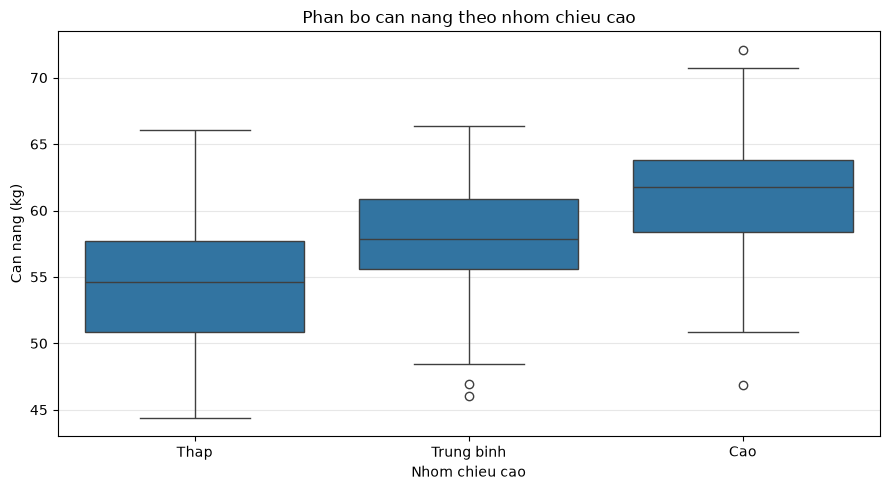


Da luu bieu do box.png


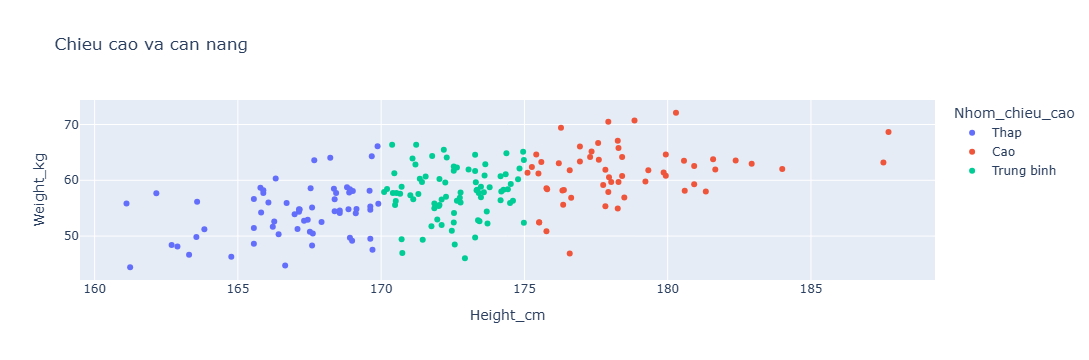


KET LUAN:
Da xu ly thanh cong du lieu 200 nguoi.
So nguoi co BMI duoi 18.5: 50
Da thong ke theo 3 nhom chieu cao.
Da luu bieu do box.png.


In [13]:
# TH 6.3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("200heightsweights.csv")
print("1. THONG TIN DU LIEU")
print("Kich thuoc:", df.shape)
print("So gia tri thieu ban dau:")
print(df.isna().sum())
df = (
    df.rename(columns={
        "Height(Inches)": "Height_in",
        "Weight(Pounds)": "Weight_lb"
    })
    .assign(
        Height_cm=lambda d: d["Height_in"] * 2.54,
        Weight_kg=lambda d: d["Weight_lb"] * 0.45359237
    )
    .assign(
        Height_cm=lambda d: d["Height_cm"].fillna(
            d["Height_cm"].mean()
        ),
        Weight_kg=lambda d: d["Weight_kg"].fillna(
            d["Weight_kg"].mean()
        )
    )
    .assign(
        BMI=lambda d: d["Weight_kg"] / (d["Height_cm"] / 100)**2
    )
)
print("\n2. DU LIEU SAU KHI XU LY")
print(df.head())
print("\nSo gia tri thieu:")
print(df[["Height_cm", "Weight_kg", "BMI"]].isna().sum())
so_nguoi = (df["BMI"] < 18.5).sum()
print("\n3. SO NGUOI CO BMI DUOI 18.5")
print(so_nguoi)
df["Nhom_chieu_cao"] = pd.cut(
    df["Height_cm"],
    bins=[-np.inf, 170, 175, np.inf],
    labels=["Thap", "Trung binh", "Cao"],
    right=False
)
print("\n4. SO NGUOI THEO NHOM CHIEU CAO")
print(df["Nhom_chieu_cao"].value_counts().sort_index())
df["BMI_duoi_18_5"] = df["BMI"] < 18.5
ty_le = (
    df.groupby("Nhom_chieu_cao", observed=True)
      ["BMI_duoi_18_5"].mean() * 100
)
print("\n5. TY LE BMI DUOI 18.5 THEO NHOM (%)")
print(ty_le.round(2))
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="Nhom_chieu_cao",
    y="Weight_kg",
    order=["Thap", "Trung binh", "Cao"]
)
plt.title("Phan bo can nang theo nhom chieu cao")
plt.xlabel("Nhom chieu cao")
plt.ylabel("Can nang (kg)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("box.png", dpi=300)
plt.show()
print("\nDa luu bieu do box.png")
try:
    import plotly.express as px
    fig = px.scatter(
        df,
        x="Height_cm",
        y="Weight_kg",
        color="Nhom_chieu_cao",
        hover_data=["BMI"],
        title="Chieu cao va can nang"
    )
    fig.show()
except ImportError:
    print("Chua cai dat Plotly, bo qua bieu do tuong tac")
assert len(df) == 200
assert df[["Height_cm", "Weight_kg", "BMI"]].isna().sum().sum() == 0
assert df["Nhom_chieu_cao"].value_counts().sum() == 200
print("\nKET LUAN:")
print("Da xu ly thanh cong du lieu 200 nguoi.")
print("So nguoi co BMI duoi 18.5:", so_nguoi)
print("Da thong ke theo 3 nhom chieu cao.")
print("Da luu bieu do box.png.")

In [ ]:
# TH 6.4
import pandas as pd
df = pd.read_csv("core_HRdata.csv")
print("1. THONG TIN DU LIEU")
print("Kich thuoc:", df.shape)
print(df.head())
df["Department"] = df["Department"].str.strip()
print("\n2. DANH SACH PHONG BAN")
print(df["Department"].unique())
print("So phong ban:", df["Department"].nunique())

# 3. Tinh luong trung binh theo phong ban va gioi tinh
bang_luong = (
    df.groupby(["Department", "Sex"])["Pay Rate"]
      .mean()
      .unstack()
)

print("\n3. LUONG TRUNG BINH THEO PHONG BAN VA GIOI TINH")
print(bang_luong.round(2).to_string())

# 4. Chuyen ngay vao lam sang datetime
df["Date of Hire"] = pd.to_datetime(
    df["Date of Hire"],
    format="%m/%d/%Y"
)

# 5. Tinh tham nien den ngay 01/01/2017
moc = pd.Timestamp("2017-01-01")

df["Tham_nien"] = (
    (moc - df["Date of Hire"]).dt.days // 365
)

print("\n4. THONG TIN THAM NIEN")
print(
    df[["Employee Name", "Date of Hire", "Tham_nien"]].head()
)

# 6. Tim 5 nhan vien co tham nien cao nhat
top5 = df.sort_values(
    ["Tham_nien", "Employee Name"],
    ascending=[False, True]
).head(5)

print("\n5. NAM NHAN VIEN CO THAM NIEN CAO NHAT")
print(
    top5[[
        "Employee Name",
        "Department",
        "Date of Hire",
        "Tham_nien"
    ]].to_string(index=False)
)

# 7. Thong ke theo Performance Score
thong_ke = df["Performance Score"].value_counts()

print("\n6. THONG KE DANH GIA NHAN VIEN")
print(thong_ke.to_string())

print("\nTong so nhan vien duoc thong ke:",
      thong_ke.sum())

# 8. Kiem tra ket qua
assert df.shape[0] == 301
assert df["Department"].nunique() == 6
assert len(top5) == 5

print("\nKET LUAN:")
print("Tong so nhan vien:", len(df))
print("So phong ban:", df["Department"].nunique())
print("Da tinh luong trung binh theo phong ban va gioi tinh.")
print("Da tim 5 nhan vien co tham nien cao nhat.")
print("Da thong ke ket qua danh gia nhan vien.")
print("HOAN THANH BAI THUC HANH 6.4!")
